# GMM mood playlists

**Question (Aisha Mensah):** what natural groups of songs exist based on how they sound, so mood playlists can be built around them?

**Approach:** transform six audio features, reduce with PCA, fit a Gaussian mixture (GMM), choose the number of groups k from the data, then build one sample playlist per group so the groups can be listened to. Group names are left until after listening.

Run top to bottom. Needs `spotify_songs_clean.csv` in the same folder.

## 1. Setup and data

In [1]:
from pathlib import Path
import itertools, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import QuantileTransformer

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 200, "display.max_columns", 30)

SEED = 42
FEATURES = ["valence", "energy", "danceability", "acousticness", "loudness", "tempo"]
PCA_VAR = 0.90                       # keep PCs covering 90% of variance
K_RANGE = range(3, 11)
MIN_K, MIN_STABILITY = 4, 0.75       # rule for choosing k (section 3)

PLAYLIST_LEN, N_BRIDGE = 20, 4       # 1 seed + 15 core + 4 bridge songs
MIN_POP, SEED_MIN_POP = 40, 60       # popularity floors (catalog median is about 43)
CORE_PROB = 0.80                     # "core member" = top group probability >= 0.8
MAX_PER_ARTIST = 2

Remixes, live cuts and other alternate versions are flagged, and duplicate versions of one song are collapsed, so a playlist does not repeat a song. All songs are still used to fit the model; the filter only decides which songs may appear in a playlist.

In [2]:
#Using cleaned data from exploratory_analysis.R
songs = pd.read_csv("spotify_songs_clean.csv")
songs["artist_key"] = songs.track_artist.str.casefold().str.strip()

ALT = re.compile(r"\b(remix|rework|bootleg|vip|live|acoustic|instrumental|demo|sessions?|stripped|unplugged|"
                 r"extended|club|dub|mashup|medley|cover|(?<!original )mix)\b", re.I)

def base_title(name):
    t = re.sub(r"\s*[\(\[][^\)\]]*[\)\]]", "", name).split(" - ")[0]     # drop (...) and " - suffix"
    return re.sub(r"\s+", " ", t).strip().casefold()

def is_alt_version(name):
    tags = re.findall(r"[\(\[]([^\)\]]*)[\)\]]", name) + name.split(" - ")[1:]
    tags = [t for t in tags if not re.match(r"\s*(feat|ft|with|prod)\b", t, re.I)]
    return any(ALT.search(t) for t in tags)

songs["is_alt_version"] = songs.track_name.map(is_alt_version)
songs["dup_key"] = songs.track_name.map(base_title) + "||" + songs.artist_key

# one row per (title, artist): originals first, then the most popular
rank = (songs.sort_values(["is_alt_version", "track_popularity"], ascending=[True, False])
             .groupby("dup_key").cumcount())
songs["eligible"] = (rank == 0) & ~songs.is_alt_version & (songs.track_popularity >= MIN_POP)
print(f"{len(songs):,} songs, {songs.eligible.sum():,} eligible for playlists")

26,159 songs, 13,497 eligible for playlists


## 2. Features: rank-normal transform + PCA

* **Transform:** acousticness and loudness are very skewed (many songs sit near acousticness = 0), which gives the GMM near-degenerate components. Mapping each feature to a normal shape by rank fixes this.
* **PCA:** removes the overlap between energy, loudness and acousticness and drops the weakest direction. With a full-covariance GMM, PCA alone does not change the fit; it mainly gives axes we can read (loadings below).

In [3]:
Xt = QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=SEED).fit_transform(songs[FEATURES])
pca = PCA(n_components=PCA_VAR, random_state=SEED).fit(Xt)
Z = pca.transform(Xt)

loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=[f"PC{i+1}" for i in range(Z.shape[1])])
loadings.loc["% variance"] = pca.explained_variance_ratio_ * 100
display(loadings.round(2))

,PC1,PC2,PC3,PC4,PC5
valence,0.00,0.67,0.31,0.36,0.55
energy,0.61,0.13,-0.11,0.16,0.03
danceability,-0.14,0.67,0.05,-0.56,-0.45
acousticness,-0.50,0.05,0.14,0.64,-0.46
loudness,0.53,0.17,-0.17,0.33,-0.50
tempo,0.25,-0.22,0.92,-0.11,-0.18
% variance,35.44,22.48,15.66,11.81,10.45


## 3. Choose k

test k = 3-10 with three measures:

* **BIC** on all songs (lower is better).
* **Held-out log-likelihood**: fit on 80% of songs, score the other 20% (higher is better).
* **Stability**: fit on six random 70% subsamples, label all songs with each fit, and average the agreement (adjusted Rand index, ARI) between fits. 1 = same groups every time.

BIC and likelihood keep improving as k grows, so we take the **largest k whose groups are still stable** (ARI >= 0.75).

c:\Users\molin\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\molin\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\molin\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\molin\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\molin\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
       

chosen k = 6


,bic,heldout_ll,stability
k,,,
3,369525.016,-7.033,0.927
4,368493.346,-7.011,0.808
5,367667.204,-6.991,0.619
6,367525.042,-6.986,0.851
7,367313.329,-6.972,0.723
8,366304.772,-6.956,0.587
9,366101.774,-6.955,0.560
10,366132.252,-6.951,0.555


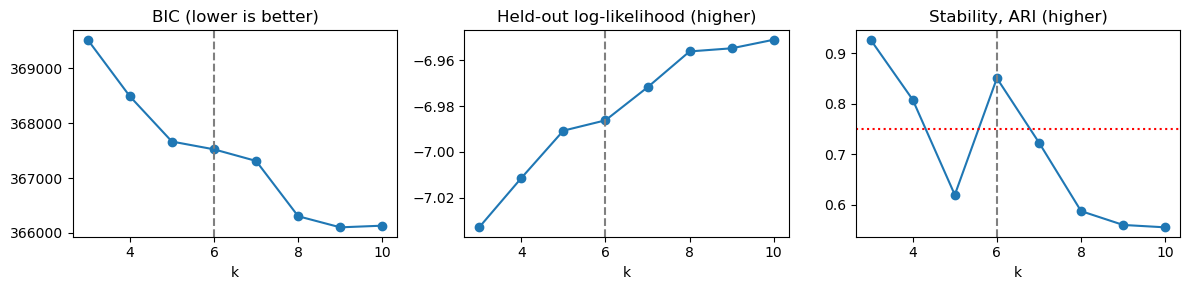

In [4]:
def fit_gmm(Z, k, seed, n_init):
    return GaussianMixture(k, covariance_type="full", n_init=n_init, max_iter=300,
                           reg_covar=1e-4, random_state=seed).fit(Z)

rng = np.random.default_rng(SEED)
n = len(Z)
idx = rng.permutation(n)
train, test = idx[:int(0.8 * n)], idx[int(0.8 * n):]
subsamples = [rng.choice(n, int(0.7 * n), replace=False) for _ in range(6)]

rows = []
for k in K_RANGE:
    bic = fit_gmm(Z, k, SEED, 4).bic(Z)
    heldout = fit_gmm(Z[train], k, SEED, 4).score(Z[test])
    labels = [fit_gmm(Z[s], k, SEED + i + 1, 3).predict(Z) for i, s in enumerate(subsamples)]
    stability = np.mean([adjusted_rand_score(a, b) for a, b in itertools.combinations(labels, 2)])
    rows.append({"k": k, "bic": bic, "heldout_ll": heldout, "stability": stability})
k_table = pd.DataFrame(rows).set_index("k")

ok = k_table[(k_table.index >= MIN_K) & (k_table.stability >= MIN_STABILITY)]
K = int(ok.index.max()) if len(ok) else int(k_table.stability.idxmax())
print("chosen k =", K)
display(k_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col, title in zip(axes, k_table.columns, ["BIC (lower is better)", "Held-out log-likelihood (higher)", "Stability, ARI (higher)"]):
    ax.plot(k_table.index, k_table[col], "o-")
    ax.axvline(K, color="grey", ls="--")
    ax.set(title=title, xlabel="k")
axes[2].axhline(MIN_STABILITY, color="red", ls=":")
plt.tight_layout(); plt.show()

## 4. Fit the groups and describe them

Each song gets a probability for every group. The table shows each group's average audio profile (original units, weighted by membership). "Core" songs have a top probability >= 0.8; the rest sit between groups.

In [5]:
gmm = fit_gmm(Z, K, SEED, 10)
assert gmm.converged_

P = gmm.predict_proba(Z)                 # soft membership, one column per group
groups = P.argmax(1)
p_max = P.max(1)
print(f"core songs (top probability >= {CORE_PROB}): {(p_max >= CORE_PROB).mean():.0%}; "
      f"borderline (< 0.6): {(p_max < 0.6).mean():.0%}")

profiles = pd.DataFrame((P / P.sum(0)).T @ songs[FEATURES].to_numpy(), columns=FEATURES)
profiles.insert(0, "group", np.arange(1, K + 1))
profiles["share_of_catalog"] = P.mean(0)
profiles["pct_core"] = [(p_max[groups == g] >= CORE_PROB).mean() for g in range(K)]
display(profiles.round(3))

core songs (top probability >= 0.8): 31%; borderline (< 0.6): 39%


,group,valence,energy,danceability,acousticness,loudness,tempo,share_of_catalog,pct_core
0,1,0.673,0.782,0.734,0.124,-5.521,109.010,0.188,0.222
1,2,0.384,0.450,0.559,0.515,-10.101,112.480,0.111,0.480
2,3,0.545,0.683,0.623,0.211,-6.713,155.068,0.165,0.464
3,4,0.421,0.692,0.626,0.175,-6.677,105.481,0.210,0.174
4,5,0.383,0.861,0.576,0.033,-4.855,134.446,0.159,0.427
5,6,0.586,0.625,0.764,0.143,-8.394,113.251,0.167,0.209


## 5. One sample playlist per group

Each playlist has 20 songs, all popular enough to recognise (>= `MIN_POP`), with no remixes, no duplicate versions and at most two songs per artist:

* **Seed:** the most typical well-known core song of the group.
* **Core (15):** the core songs are split into 15 sub-neighbourhoods and the most popular typical song of each is taken, so the playlist covers the group instead of clustering around the seed.
* **Bridge (4):** popular songs split between this group and a neighbouring one, labelled with that neighbour. They show where groups blend.

A song is used in only one playlist.

In [6]:
pop = songs.track_popularity.to_numpy()
artist = songs.artist_key.to_numpy()
eligible = songs.eligible.to_numpy()

def make_playlists():
    n_core = PLAYLIST_LEN - 1 - N_BRIDGE
    used, lists = set(), []
    for g in range(K):
        count = {}
        def take(i):
            used.add(i); count[artist[i]] = count.get(artist[i], 0) + 1
        def ok(i):
            return i not in used and count.get(artist[i], 0) < MAX_PER_ARTIST

        # eligible core songs of group g, measured in the group's own (whitened) space
        pool = np.flatnonzero(eligible & (groups == g) & (P[:, g] >= CORE_PROB))
        W = (Z[pool] - gmm.means_[g]) @ np.linalg.cholesky(gmm.precisions_[g])
        d2 = (W ** 2).sum(1)

        # seed
        known = np.flatnonzero(pop[pool] >= SEED_MIN_POP)
        s = known[np.argmin(d2[known])] if len(known) else np.argmin(d2)
        take(pool[s])

        # core: one song per sub-neighbourhood of the typical region (nearest 80%)
        cand = np.flatnonzero((d2 <= np.quantile(d2, 0.8)) & (np.arange(len(pool)) != s))
        km = KMeans(n_core, n_init=5, random_state=SEED).fit(W[cand])
        core = []
        for c in range(n_core):
            members = cand[km.labels_ == c]
            near = members[np.argsort(((W[members] - km.cluster_centers_[c]) ** 2).sum(1))]
            options = sorted(near[:8], key=lambda j: -pop[pool[j]]) + list(near[8:])
            pick = next((pool[j] for j in options if ok(pool[j])), None)
            if pick is not None:
                take(pick); core.append(pick)

        # bridge: popular songs split between group g and one neighbour
        P_other = P.copy(); P_other[:, g] = -1
        neighbour = P_other.argmax(1)
        split = eligible & (P[:, g] >= 0.35) & (P[:, g] <= 0.65) & (P[:, g] + P_other.max(1) >= 0.85)
        bridge = []
        for i in sorted(np.flatnonzero(split), key=lambda i: -pop[i]):
            if len(bridge) == N_BRIDGE:
                break
            if ok(i):
                take(i); bridge.append(i)

        idx = [pool[s]] + core + bridge
        roles = ["seed"] + ["core"] * len(core) + [f"bridge (also group {neighbour[i] + 1})" for i in bridge]
        pl = songs.iloc[idx][["track_id", "track_name", "track_artist", "playlist_genre", "track_popularity"]].copy()
        pl.insert(0, "role", roles)
        pl.insert(0, "position", np.arange(1, len(pl) + 1))
        pl.insert(0, "playlist", g + 1)
        pl["p_group"] = P[idx, g]
        lists.append(pl)
    return pd.concat(lists, ignore_index=True)

playlists = make_playlists()
assert playlists.groupby("playlist").size().eq(PLAYLIST_LEN).all() and playlists.track_id.is_unique

for g, pl in playlists.groupby("playlist"):
    p = profiles.iloc[g - 1]
    print(f"\nPlaylist {g}: energy {p.energy:.2f}, valence {p.valence:.2f}, acousticness {p.acousticness:.2f}, tempo {p.tempo:.0f} BPM")
    display(pl.drop(columns=["playlist", "track_id"]).round(2).reset_index(drop=True))

c:\Users\molin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\molin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\molin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(



Playlist 1: energy 0.78, valence 0.67, acousticness 0.12, tempo 109 BPM


c:\Users\molin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\molin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\molin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,position,role,track_name,track_artist,playlist_genre,track_popularity,p_group
0,1,seed,"My Love (feat. Major Lazer, WizKid, Dua Lipa)",Wale,pop,64,0.81
1,2,core,Booty,C. Tangana,latin,71,0.87
2,3,core,Como Antes (feat. Wisin),Yandel,latin,67,0.93
3,4,core,Adictiva,Daddy Yankee,rap,77,0.92
4,5,core,Nadie Como Tu,Amenazzy,rap,67,0.82
5,6,core,God Is A Dancer (with Mabel),Tiësto,edm,82,0.88
6,7,core,"Taki Taki (with Selena Gomez, Ozuna & Cardi B)",DJ Snake,pop,83,0.89
7,8,core,Fantasias,Rauw Alejandro,pop,92,0.86
8,9,core,Stack It Up (feat. A Boogie Wit da Hoodie),Liam Payne,r&b,76,0.88
9,10,core,Thriller,Michael Jackson,pop,68,0.87



Playlist 2: energy 0.45, valence 0.38, acousticness 0.52, tempo 112 BPM


,position,role,track_name,track_artist,playlist_genre,track_popularity,p_group
0,1,seed,Reminiscing - Remastered,Little River Band,rock,62,0.82
1,2,core,Alone,Heart,rock,73,0.88
2,3,core,Devil Eyes,Hippie Sabotage,pop,81,0.97
3,4,core,Dust in the Wind,Kansas,rock,77,0.84
4,5,core,ocean eyes,Billie Eilish,r&b,85,0.91
5,6,core,Get You (feat. Kali Uchis),Daniel Caesar,r&b,78,0.82
6,7,core,Love Songs - Bonus,Kaash Paige,r&b,80,0.85
7,8,core,1950,King Princess,latin,79,0.85
8,9,core,Mr. Blue Sky,Electric Light Orchestra,rock,79,0.87
9,10,core,Best Part (feat. H.E.R.),Daniel Caesar,pop,79,0.86


... (4 outputs left out)


Playlist 5: energy 0.86, valence 0.38, acousticness 0.03, tempo 134 BPM


,position,role,track_name,track_artist,playlist_genre,track_popularity,p_group
0,1,seed,Metaphor,Alok,edm,61,0.90
1,2,core,Purple Lamborghini (with Rick Ross),Skrillex,pop,72,0.97
2,3,core,Any Way You Want It,Journey,pop,71,0.92
3,4,core,Stars,VIZE,edm,72,0.81
4,5,core,World At Our Feet,Timmy Trumpet,edm,64,0.86
5,6,core,Slither,Velvet Revolver,rock,63,0.96
6,7,core,Golden Skans,Klaxons,rock,64,0.95
7,8,core,Memories (feat. Kid Cudi),David Guetta,rap,66,0.89
8,9,core,Savin' Me,Nickelback,rock,64,0.93
9,10,core,(Don't Fear) The Reaper,Blue Öyster Cult,rock,75,0.97



Playlist 6: energy 0.62, valence 0.59, acousticness 0.14, tempo 113 BPM


,position,role,track_name,track_artist,playlist_genre,track_popularity,p_group
0,1,seed,Together Again,Janet Jackson,r&b,67,0.81
1,2,core,Stuck In The Middle With You,Stealers Wheel,rock,71,0.89
2,3,core,Shotta Flow,NLE Choppa,rap,76,0.86
3,4,core,Faith - Remastered,George Michael,pop,75,0.90
4,5,core,Press,Cardi B,r&b,74,0.86
5,6,core,Monkey Gone to Heaven,Pixies,rock,61,0.80
6,7,core,Listen to the Music,The Doobie Brothers,rock,75,0.92
7,8,core,I Can't Dance - 2007 Digital Remaster,Genesis,rock,61,0.87
8,9,core,Thotiana,Blueface,pop,78,0.88
9,10,core,Chill Bill (feat. J. Davi$ & Spooks),Rob $tone,rap,77,0.94


## 6. Export

In [7]:
out = Path("results"); out.mkdir(exist_ok=True)
membership = songs[["track_id", "track_name", "track_artist"]].copy()
for g in range(K):
    membership[f"p_group_{g+1}"] = P[:, g]
membership["group"] = groups + 1
membership["p_max"] = p_max

membership.to_csv(out / "song_membership.csv", index=False, encoding="utf-8-sig")
profiles.to_csv(out / "group_profiles.csv", index=False, encoding="utf-8-sig")
playlists.to_csv(out / "playlists.csv", index=False, encoding="utf-8-sig")